# Cat Swarm Optimization (CSO) for quadrotor controller tuning

**Author: Mohammad ALbaraj**

[Notebook index](README.md) · [Main project](../README.md)

Run cells from top to bottom. Saved results and fresh examples are labeled separately. Scientific source modules remain the authoritative implementation.


In [1]:
from pathlib import Path
import sys, json, csv
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Code

# Works when launched from the repository root or any notebook subdirectory.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'CITATION.cff').exists() and (p / 'all work').is_dir())
if str(ROOT / 'notebooks') not in sys.path:
    sys.path.insert(0, str(ROOT / 'notebooks'))
from notebook_support import (METHODS, ORIGINAL, NOMINAL, ROBUST, study, load_json,
    load_csv, show_table, show_source, source_index, load_runs, fitness_summary,
    convergence_plot, validation_rows, validation_summary, figures, file_links,
    show_figures, gallery, isolated_python, demo_source)
plt.rcParams.update({'figure.dpi': 100, 'font.size': 10})
print('Project loaded. Default cells do not launch full optimization campaigns.')


Project loaded. Default cells do not launch full optimization campaigns.


## Algorithm walkthrough

This implementation alternates seeking and tracing modes and keeps a best archive across every evaluated trial, including trials not selected as a cat's next position.

1. Initialize 64 cats in normalized log-gain space and include the original controller.
2. Randomly assign 13 cats to tracing each iteration (round(64 × 0.2)); the others seek.
3. A seeking cat considers five candidates, including its current position. Each new copy multiplies four randomly chosen coordinates by 1 ± 0.2 and clips to [0, 1].
4. Select among seeking copies with probabilities proportional to `worst_fitness - candidate_fitness`; use uniform probabilities if all scores tie.
5. A tracing cat updates `v = v + 2*r*(archive_best-x)` and then moves. Velocity is capped at ±0.2, with boundary damping 0.5.
6. Reassign modes and repeat for 50 updates.

Seeking creates multiple evaluations per cat. Equal iteration counts therefore do not give equal computation across algorithms. CSO tracing does not use PSO's personal-best term or decreasing inertia.

Read [cso.py](../all%20work/pid%20using%20cat%20swarm/cso.py) for the implemented update rules, [config.json](../all%20work/pid%20using%20cat%20swarm/config.json) for settings, and [study.py](../all%20work/pid%20using%20cat%20swarm/study.py) for objective evaluation.


In [2]:
METHOD='CSO'
FOLDER=study(METHOD)
cfg=load_json(FOLDER/'config.json')
show_table([{'setting':k,'value':v} for k,v in cfg.items() if k!='parameters'],limit=60)


setting,value
study_name,Equation-based Cat Swarm Optimization of AttitudeControl_Sim
integration_dt_s,0.001
controller_dt_s,0.001
mixer_dt_s,0.004
pre_step_s,0.2
response_horizon_s,3.0
settling_band_fraction,0.02
minimum_final_hold_s,0.25
max_overshoot_fraction,0.1
max_final_error_fraction,0.02


## Exact implementation
This displays the authoritative Python source rather than a separately reimplemented optimizer. The six extensions share one module containing their distinct update rules.


In [3]:
show_source(FOLDER/METHODS[METHOD][2])


"""Bounded two-mode Cat Swarm Optimization with an all-evaluations best archive.

Reference: Chu, Tsai & Pan, PRICAI 2006. Coordinate scaling, batch scheduling,
archive policy and boundary handling are documented in STUDY_METHOD.md.
"""
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path
import json,time
import numpy as np
from model import baseline
from study import decode,encode,evaluate,write_csv

def selection_probabilities(values):
    values=np.asarray(values,dtype=float)
    weights=values.max()-values
    if weights.sum()<=0: return np.full(len(values),1/len(values))
    return weights/weights.sum()

def cat_swarm(cfg,scenarios,seed,outdir,initial=None,label='main',objective=None):
    outdir=Path(outdir); outdir.mkdir(parents=True,exist_ok=True)
    n=int(cfg['swarm_size']); d=len(cfg['parameters']); smp=int(cfg['seeking_memory_pool'])
    if n<2 or smp<2 or cfg['iterations']<1: raise ValueError('Need >=2 cats, SMP>=2 and >=1 iteration.')
    if not 0<=cfg['mixture_ratio']<=1: raise ValueError('MR must be in [0,1].')
    rng=np.random.default_rng(seed)
    x=rng.random((n,d))
    for j in range(d): x[:,j]=(rng.permutation(n)+rng.random(n))/n
    x[0]=encode(baseline(cfg['controller_dt_s']),cfg)
    if initial is not None: x[1]=encode(np.asarray(initial),cfg)
    v=rng.uniform(-cfg['initial_velocity_limit'],cfg['initial_velocity_limit'],(n,d))
    tracing_count=int(round(n*cfg['mixture_ratio']))
    change_count=max(1,min(d,int(round(d*cfg['dimensions_to_change_fraction']))))
    names=[p['name'] for p in cfg['parameters']]
    archive=x[0].copy(); best=float('inf'); cache={}; history=[]; cat_rows=[]; evaluations=[]
    start=time.perf_counter(); proposals=0; iteration=0
    def raw_score(unit):
        gains=decode(unit,cfg)
        f=objective(gains) if objective is not None else evaluate(gains,scenarios,cfg)
        return float(f) if np.isfinite(f) else 1e12
    # Compile once; its result is consumed rather than evaluated a second time.
    first_value=raw_score(x[0])
    with ThreadPoolExecutor(max_workers=cfg['workers']) as pool:
        def evaluate_points(points):
            nonlocal archive,best,proposals,first_value
            proposals+=len(points)
            keys=[tuple(np.round(p,13)) for p in points]
            new={}
            for key,p in zip(keys,points):
                if key not in cache and key not in new: new[key]=p.copy()
            items=list(new.items()); todo=[]; scores={}
            first_key=tuple(np.round(x[0],13))
            for key,p in items:
                if first_value is not None and key==first_key:
                    scores[key]=first_value; first_value=None
                else: todo.append((key,p))
            for (key,p),f in zip(todo,pool.map(raw_score,[p for _,p in todo])): scores[key]=f
            # Deterministic evaluation order independent of worker completion order.
            for key,p in items:
                f=scores[key]; cache[key]=f
                if f<best: best=f; archive=p.copy()
                evaluations.append({'evaluation':len(cache),'iteration':iteration,'fitness':f,
                                    'best_so_far':best,**dict(zip(names,decode(p,cfg)))})
            return np.array([cache[k] for k in keys])
        values=evaluate_points(x)
        modes=np.full(n,'initial',dtype='<U8')
        for iteration in range(cfg['iterations']+1):
            if iteration:
                modes[:]='seeking'
                if tracing_count: modes[rng.choice(n,tracing_count,replace=False)]='tracing'
                points=[]; spans=[]; nextv=v.copy(); frozen_best=archive.copy()
                for i in range(n):
                    begin=len(points)
                    if modes[i]=='tracing':
                        nextv[i]=np.clip(v[i]+cfg['tracing_coefficient']*rng.random(d)*(frozen_best-x[i]),
                                         -cfg['velocity_limit'],cfg['velocity_limit'])
                        trial=x[i]+nextv[i]; hit

## Original three-seed study
These iteration-based results are separate from the strict-budget benchmark below. Unique evaluation counts differ across methods.


In [4]:
original_runs=[load_json(FOLDER/f'results/run_main_{seed}.json') for seed in [11,29,47]]
show_table(original_runs,['seed','fitness','unique_evaluations','seconds'])
show_table([{'gain':k,'value':v} for k,v in load_json(FOLDER/'results/best_gains.json')['gains'].items()])


seed,fitness,unique_evaluations,seconds
11,0.06237403060761272,10891,60.47665389999747
29,0.06216829916316375,10884,40.23423020000337
47,0.06414133576792916,10890,40.44482520001475


gain,value
roll_outer_K,13.806324491143846
roll_inner_Kp_equivalent,0.06801398794867135
roll_inner_Ki_equivalent,0.00010618596621273439
pitch_outer_K,11.470003585300924
pitch_inner_Kp_equivalent,0.06801398794867132
pitch_inner_Ki_equivalent,0.0003109079091542351
yaw_Kp,0.38616527457689814
yaw_Ki,0.02847468604274034


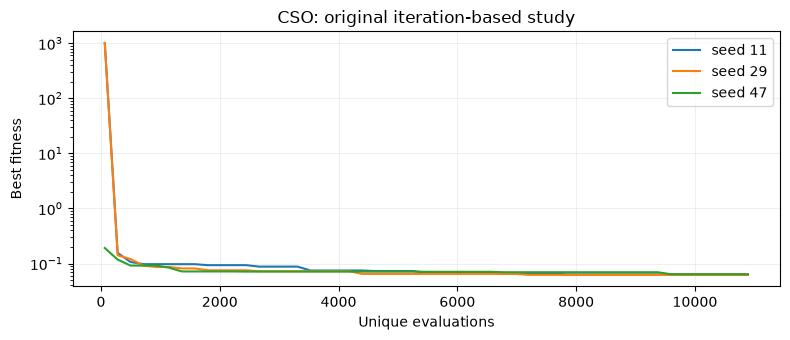

In [5]:
fig,ax=plt.subplots(figsize=(8,3.5))
for record in original_runs:
    history=record['history']
    ax.plot([h['unique_evaluations'] for h in history],[h['best'] for h in history],label=f"seed {record['seed']}")
ax.set(xlabel='Unique evaluations',ylabel='Best fitness',yscale='log',title=f'{METHOD}: original iteration-based study')
ax.legend(); ax.grid(alpha=.2); fig.tight_layout(); plt.show(); plt.close(fig)


## Paired 30-seed results
These summaries are recomputed from saved run records. Nominal and robust fitness use different training sets. Means retain infeasible penalties; medians alone can hide a failed run.


method,regime,runs,best,median,mean,sample_sd,feasible
CSO,nominal,30,0.05797834584155963,0.06714704781071607,0.06894582617207273,0.006431856988668625,30
CSO,robust,30,0.07536530816958906,0.08594910805458739,0.0864914037604736,0.006837963816693089,30


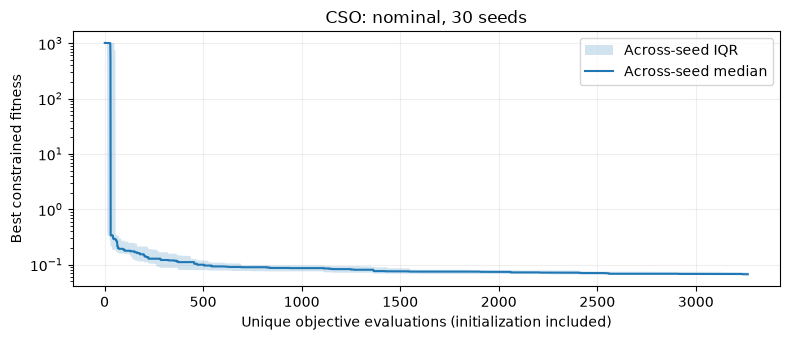

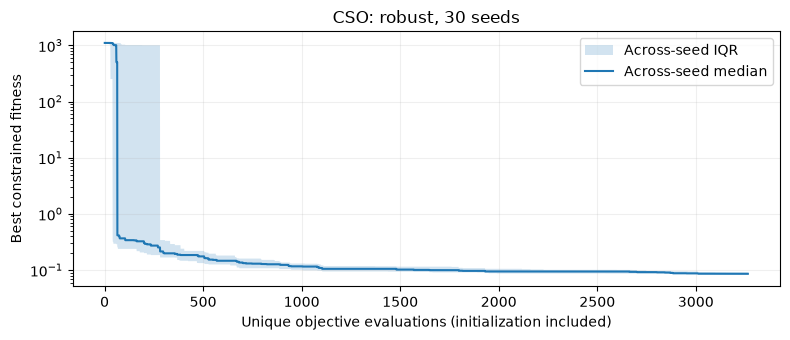

In [6]:
show_table(fitness_summary([METHOD]))
convergence_plot(METHOD,"nominal")
convergence_plot(METHOD,"robust")


## Held-out validation
Each later validation suite contains 300 random single-axis, 54 one-factor boundary, and 90 combined-axis cases. The table gives the range across seeds, not an independent probability of hardware success.


In [7]:
show_table(validation_summary(METHOD))


method,training,suite,cases_per_controller,minimum_passes,median_passes,maximum_passes
CSO,nominal,Random single-axis,300,244,298.5,300
CSO,nominal,One-factor boundaries,54,46,52.0,54
CSO,nominal,Combined-axis stress,90,0,0.0,0
CSO,robust,Random single-axis,300,300,300.0,300
CSO,robust,One-factor boundaries,54,53,54.0,54
CSO,robust,Combined-axis stress,90,0,0.0,0


## Saved figures
The first three images are previews; the full index below links every saved PNG for this method. The complete gallery notebook covers all methods.


**all work/pid using cat swarm/results/plots/01_step_responses.png**

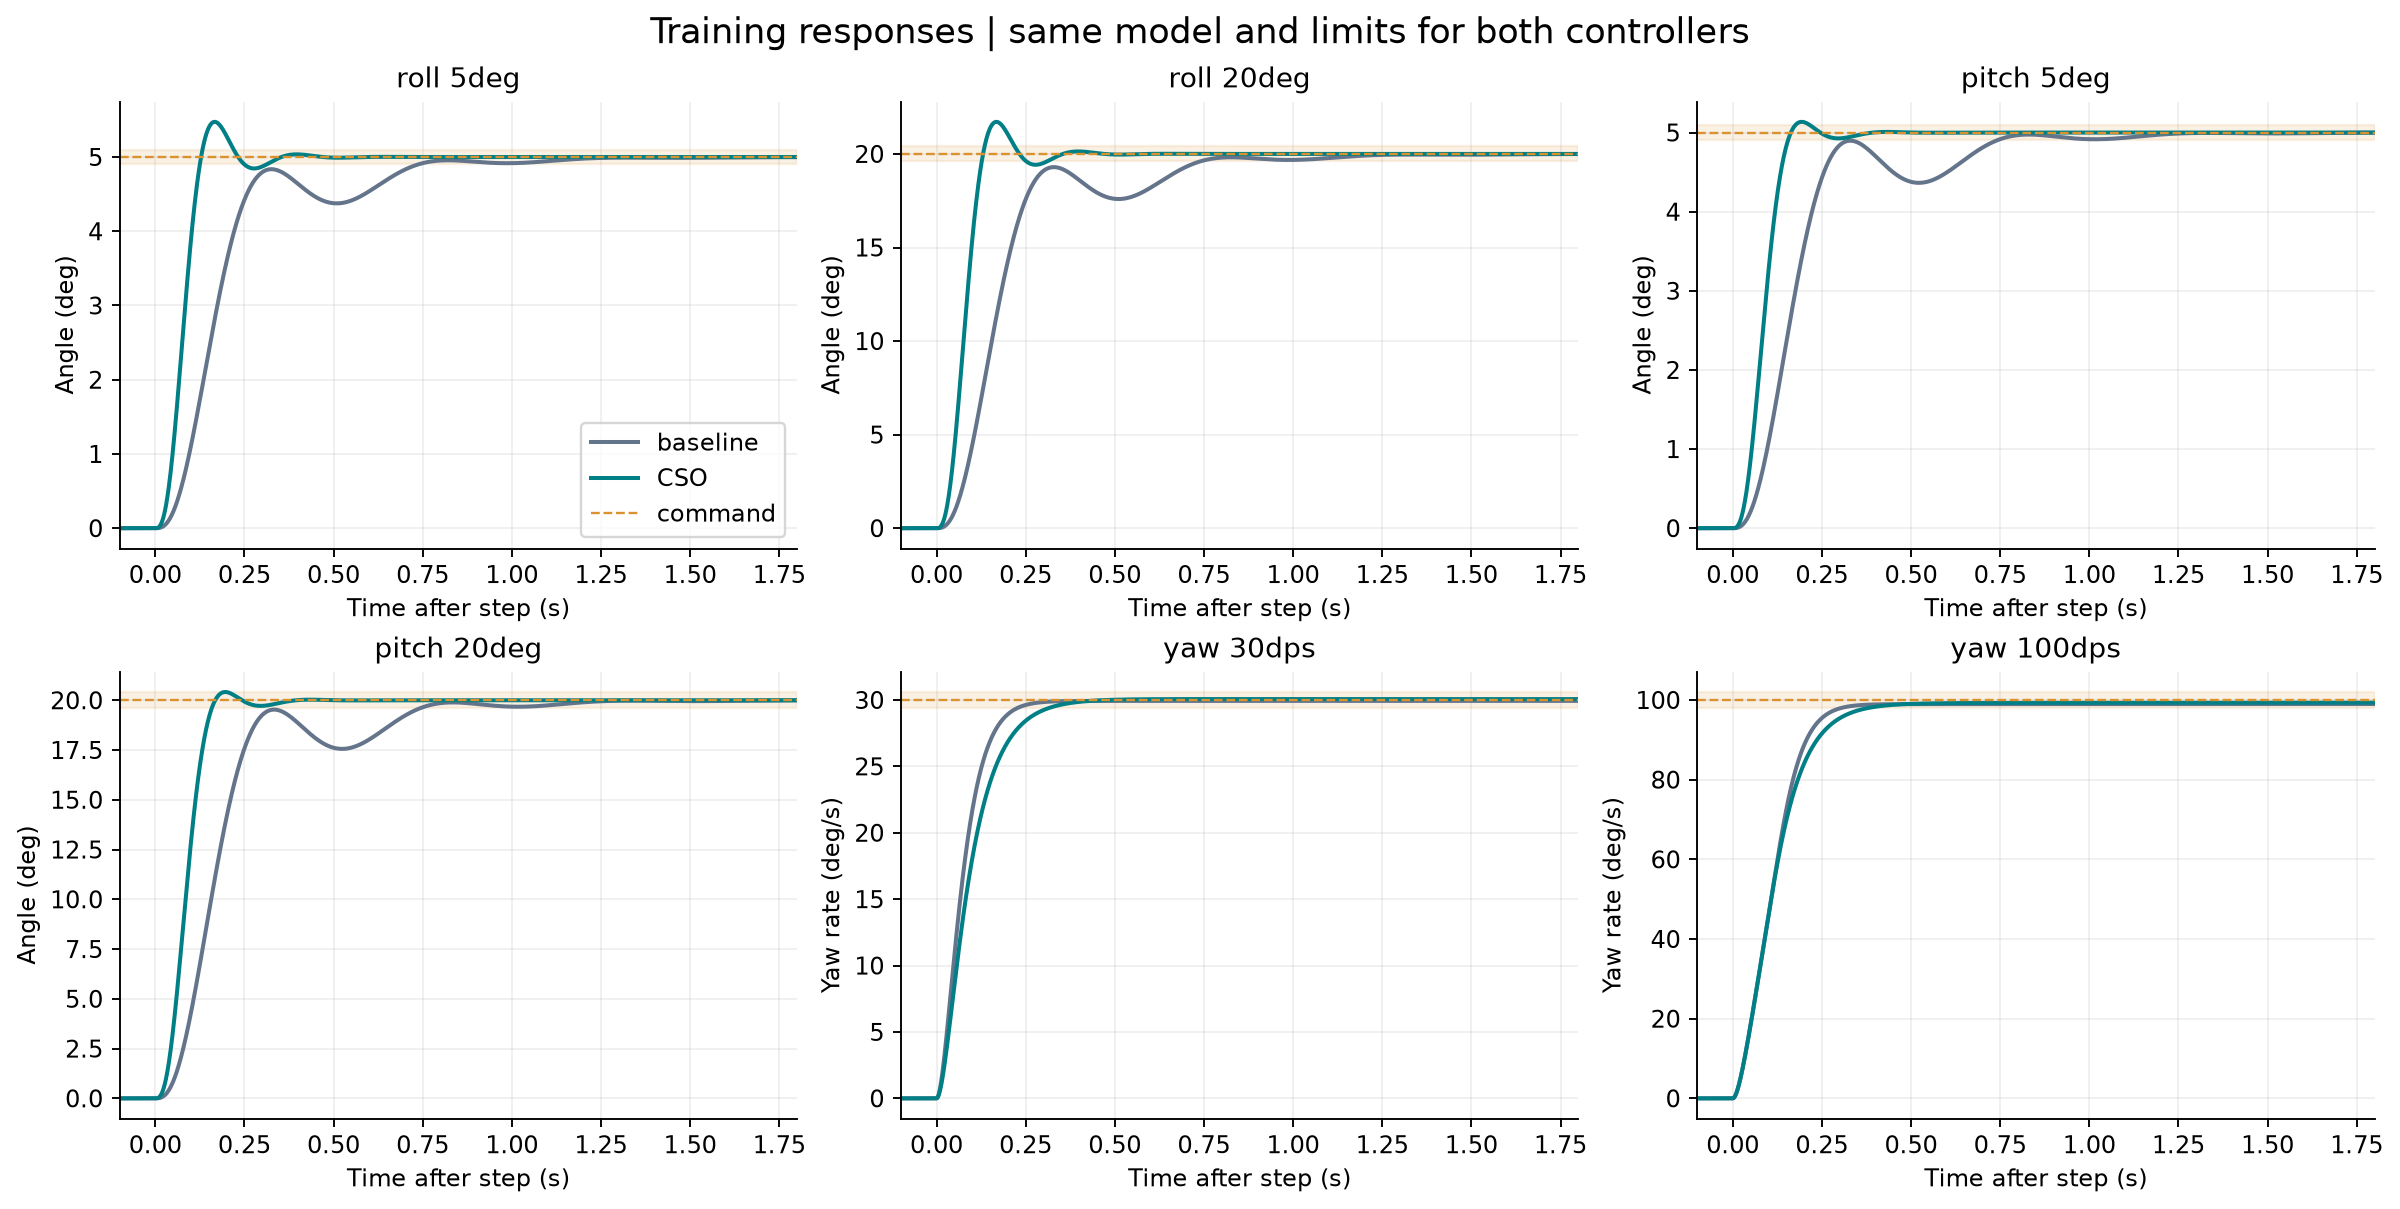

**all work/pid using cat swarm/results/plots/02_cso_iterations.png**

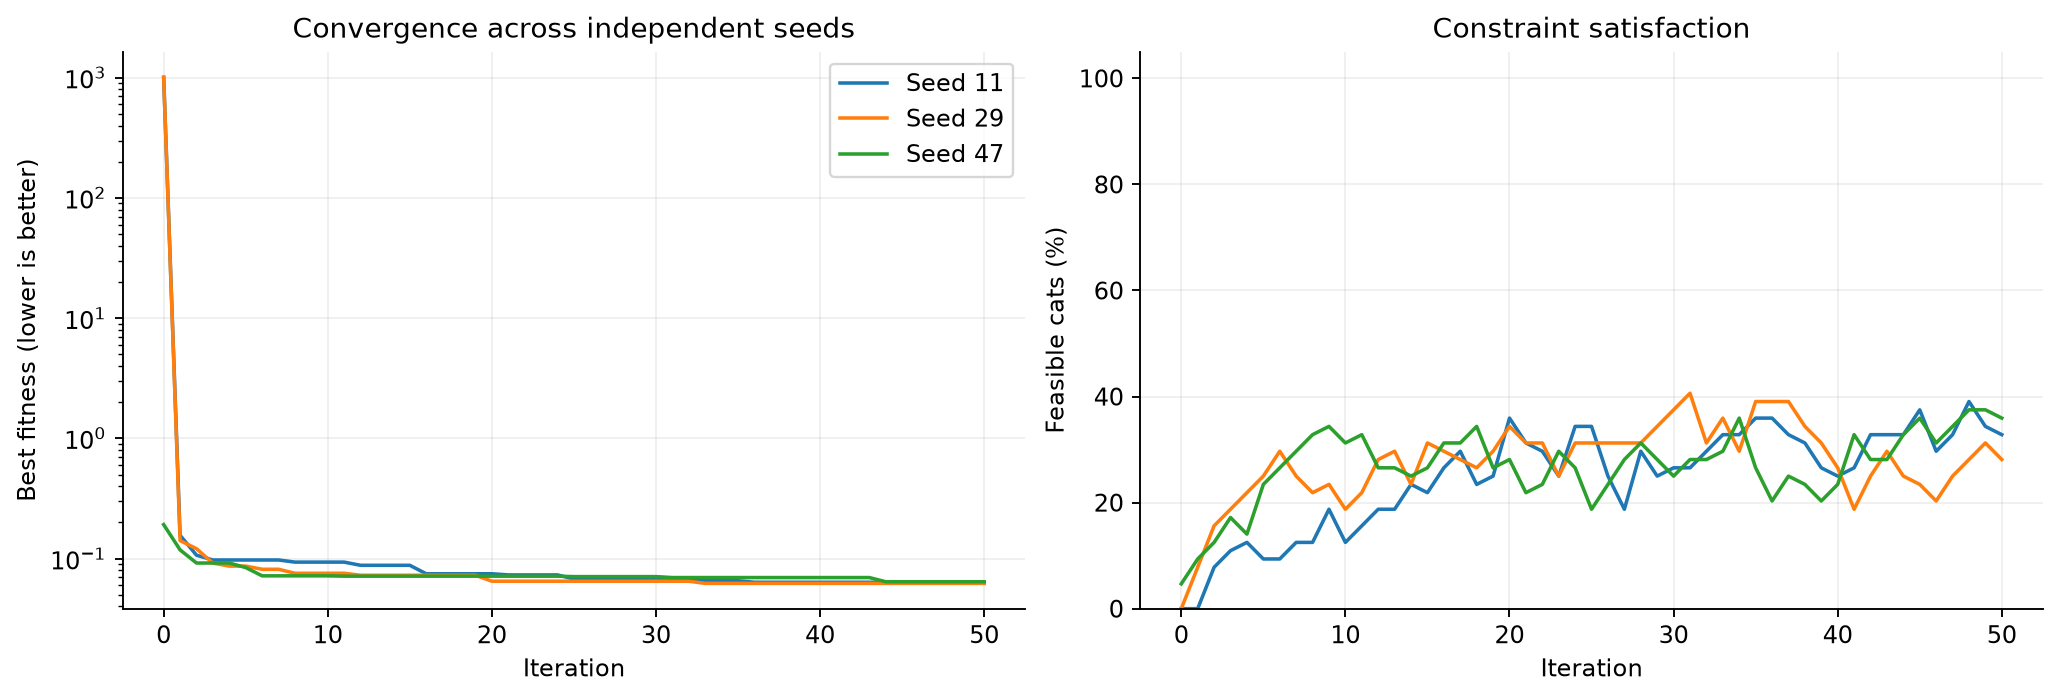

**all work/pid using cat swarm/results/plots/03_coupled_and_saturation.png**

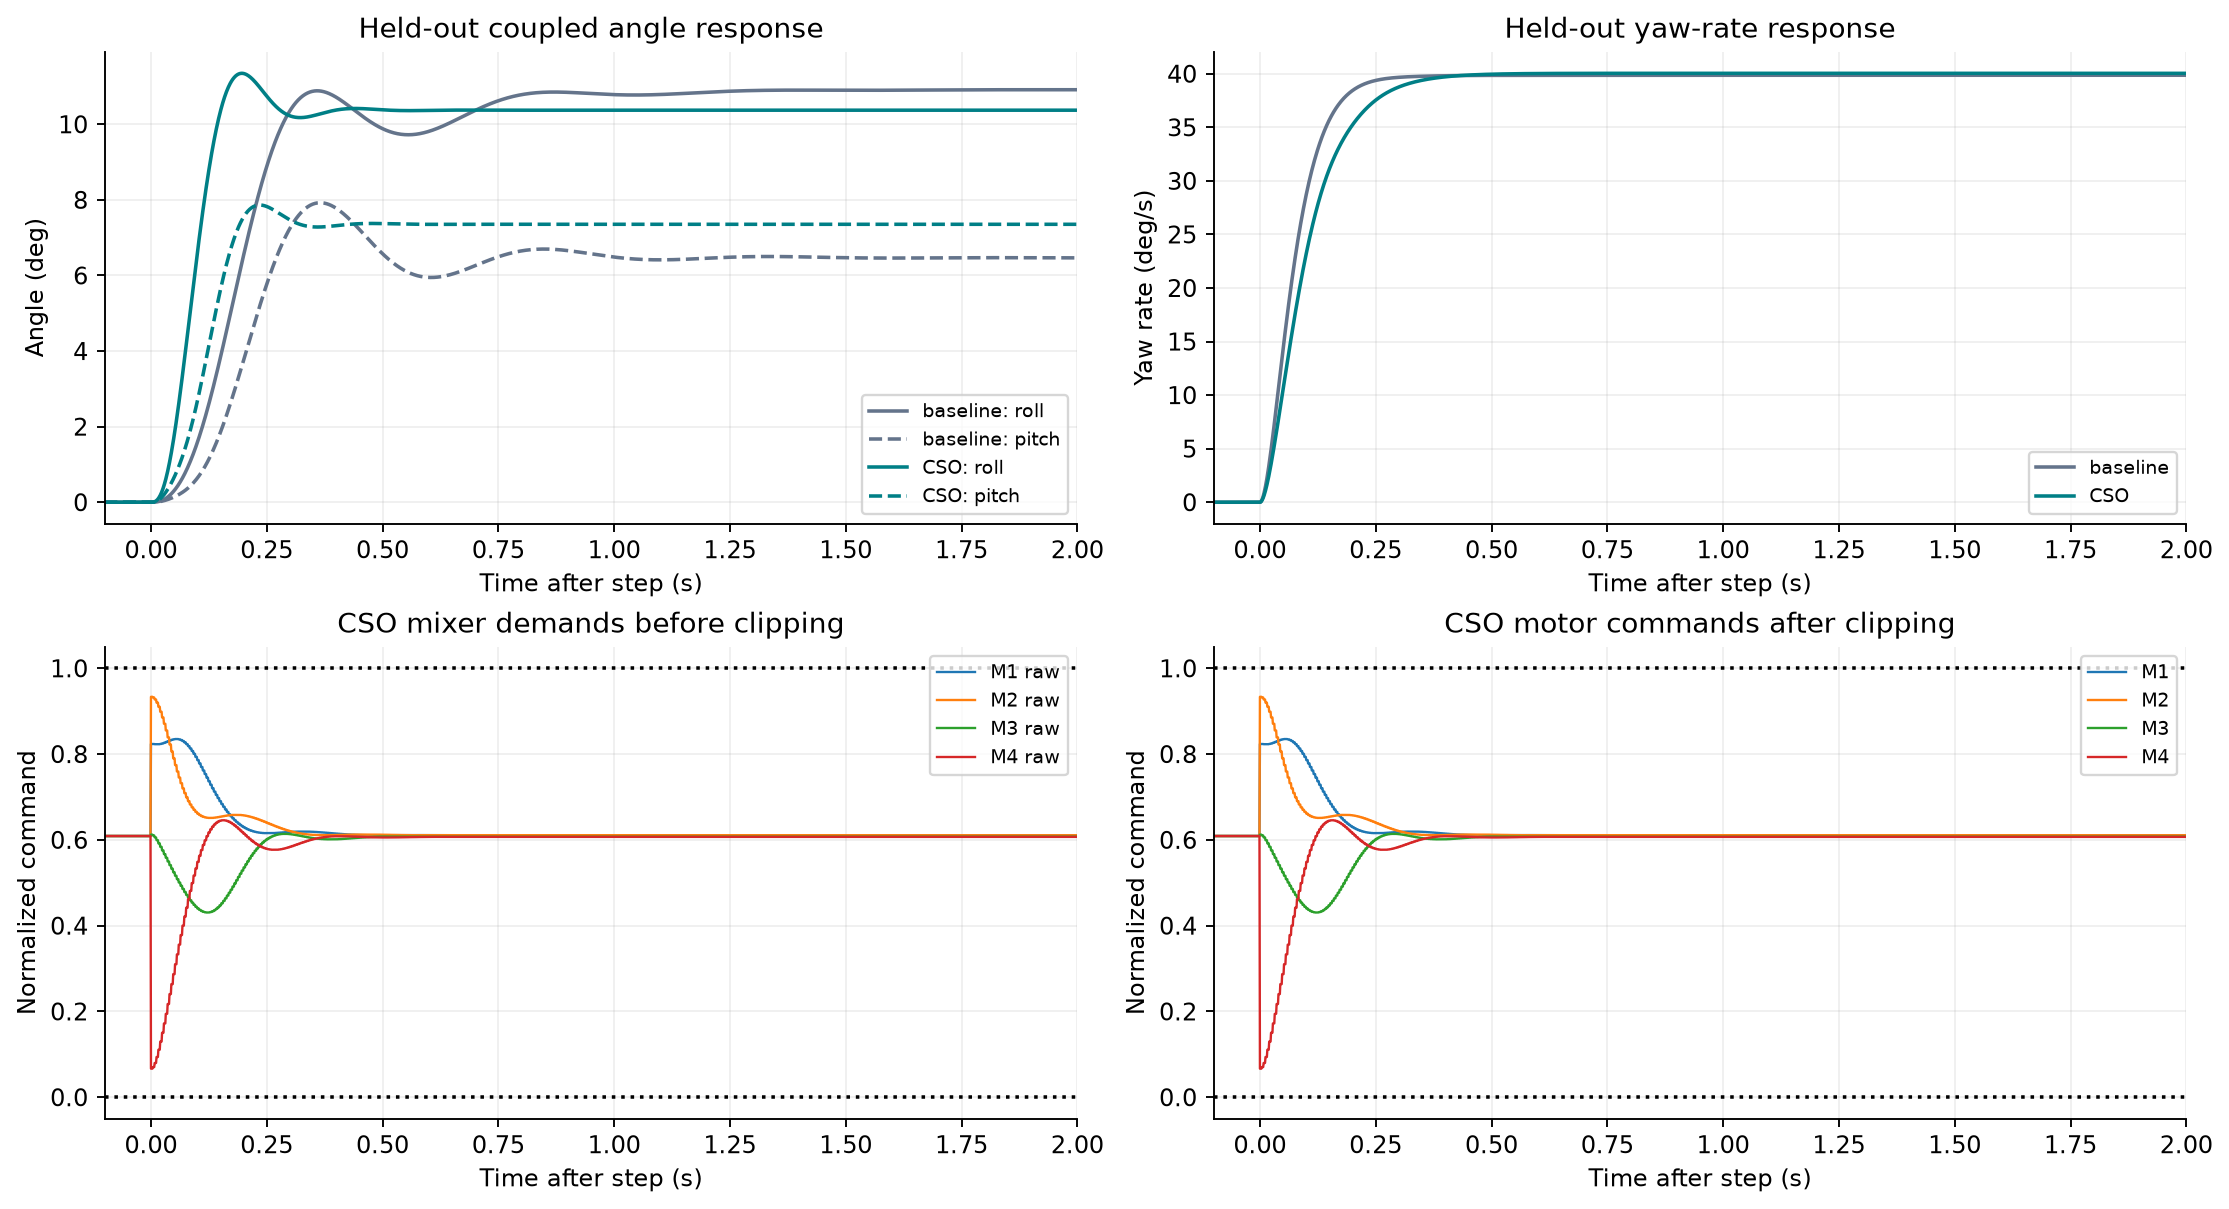

### All saved method figures
- [all work/pid using cat swarm/results/plots/01_step_responses.png](../all%20work/pid%20using%20cat%20swarm/results/plots/01_step_responses.png)
- [all work/pid using cat swarm/results/plots/02_cso_iterations.png](../all%20work/pid%20using%20cat%20swarm/results/plots/02_cso_iterations.png)
- [all work/pid using cat swarm/results/plots/03_coupled_and_saturation.png](../all%20work/pid%20using%20cat%20swarm/results/plots/03_coupled_and_saturation.png)
- [all work/pid using cat swarm/results/plots/04_inner_loops.png](../all%20work/pid%20using%20cat%20swarm/results/plots/04_inner_loops.png)
- [all work/pid using cat swarm/results/plots/05_robustness.png](../all%20work/pid%20using%20cat%20swarm/results/plots/05_robustness.png)
- [all work/pid using cat swarm/results/plots/06_gain_sensitivity.png](../all%20work/pid%20using%20cat%20swarm/results/plots/06_gain_sensitivity.png)
- [all work/pid using cat swarm/results/plots/07_metric_comparison.png](../all%20work/pid%20using%20cat%20swarm/results/plots/07_metric_comparison.png)
- [all work/pid using cat swarm/results/plots/08_fitness_components.png](../all%20work/pid%20using%20cat%20swarm/results/plots/08_fitness_components.png)
- [all work/pid using cat swarm/results/plots/09_robust_candidate.png](../all%20work/pid%20using%20cat%20swarm/results/plots/09_robust_candidate.png)
- [all work/pid using cat swarm/results/plots/10_method_responses.png](../all%20work/pid%20using%20cat%20swarm/results/plots/10_method_responses.png)
- [all work/pid using cat swarm/results/plots/11_evaluation_comparison.png](../all%20work/pid%20using%20cat%20swarm/results/plots/11_evaluation_comparison.png)

In [8]:
method_figures=figures(METHOD)
show_figures(method_figures,limit=3)
file_links(method_figures,"All saved method figures")


## Try a small fresh optimization (opt-in)
The displayed code uses the original implementation. It runs a small nominal search in `notebook_outputs/`, not the full published experiment. Set the switch to True to execute; new results are not comparable to the full-budget archive.


In [9]:
small_search_code=demo_source(METHOD)
display(Code(small_search_code,language="python"))
RUN_SMALL_SEARCH=False
if RUN_SMALL_SEARCH:
    isolated_python(METHOD,small_search_code,timeout=600)
else:
    print("Small search disabled. Set RUN_SMALL_SEARCH=True to execute.")


from pathlib import Path
import json, os
cfg=json.loads(Path('config.json').read_text())
out=Path(os.environ['PID_NOTEBOOK_OUTPUT'])/'small_search'
out.mkdir(exist_ok=True)
from study import training_scenarios
from cso import cat_swarm
cfg.update(population=8,swarm_size=8,generations=2,iterations=2,workers=1)
result=cat_swarm(cfg,training_scenarios(),2026,out)
print('Fresh small-search fitness:',result['fitness'])

Small search disabled. Set RUN_SMALL_SEARCH=True to execute.


## Full experiment and limitations
Use the linked study README for full commands, exact output files, and interpretation. Never run a modified protocol into the archived `results/`. The notebooks do not certify continuous-range robustness, global optimality, Simulink equivalence, or hardware readiness.

[Detailed study guide](../all%20work/pid%20using%20cat%20swarm/README.md) · [Data checks](../docs/DATA.md)
